# ACDC – Amazing Creative Desk Coworking
## Deliverable 1: Exploratory Data Analysis
**Data Mining · NOVA IMS · Fall 2026/27 · GroupXX**

Following CRISP-DM, this notebook covers **Business Understanding**, **Data Understanding** and the exploratory part of **Data Preparation**:

1. Business understanding
2. Setup & data loading
3. First look at the data
4. Data quality audit
5. Cleaning (rule-based corrections only)
6. Univariate analysis
7. Bivariate analysis
8. Feature engineering
9. Summary of findings and implications for clustering

## 1. Business Understanding
ACDC wants to segment its coworking members to tailor services, perks and marketing. The guidelines ask for (at least) two perspectives:
- **Value-based:** who generates revenue (lifetime value, revenue per month, tier).
- **Behavioral:** how members use the space (attendance, utilisation of their plan, add-ons).

The EDA goal is therefore to (a) understand data quality risks for clustering, (b) find variables that discriminate between members, and (c) engineer features that describe value and behavior more richly than the raw columns.

## 2. Setup & Data Loading

> 💡 **What this step does:** Loads the libraries and sets the data path. The helper `save()` stores each figure in a `figures/` folder so it can be reused in the slides.

In [1]:
import warnings
warnings.filterwarnings("ignore")
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
sns.set_theme(style="whitegrid", palette="deep")

DATA_PATH = Path("acdc_dataset.csv")
FIG_DIR = Path("figures"); FIG_DIR.mkdir(exist_ok=True)

def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=200, bbox_inches="tight")

The file is **semicolon-separated** (a default `read_csv` call fails). We read everything as raw strings first so that no value is silently coerced before we audit it.

> 💡 **What this step does:** Reads the file with every column as text (`dtype=str`), so we can see the values exactly as stored before pandas converts anything. Note the `;` separator.

In [2]:
raw = pd.read_csv(DATA_PATH, sep=";", dtype=str, keep_default_na=False, na_values=[""])
print(f"Shape: {raw.shape[0]:,} rows × {raw.shape[1]} columns")
raw.head()

Shape: 15,465 rows × 31 columns


,member_id,age,gender,industry,country,is_team_account,n_colleagues_on_account,plan_tier,plan_days_per_week,membership_start,membership_end,last_badge_swipe,days_since_last_visit,total_visits,avg_weekly_visits,entitled_visits_last_period,actual_visits_last_period,meeting_room_hours,event_space_hours,guest_passes_issued,uses_meeting_rooms,uses_event_space,uses_guest_passes,uses_print,uses_mail_handling,uses_phone_booths,uses_day_passes,uses_storage,uses_bike_locker,n_renewals,lifetime_value
0,CW000001,38.0,Female,Information Technology,Portugal,False,0,flex,3,2021-08-01,2023-03-06,2023-03-23,-17,220,2.65,26.09,22,0.0,0.0,18.0,False,False,True,0,False,True,True,False,False,2,4477.97
1,CW000002,38.0,Male,Information Technology,Portugal,True,2,HOT_DESK,2,2023-11-24,1970-01-01,2023-11-24,37,2,0.32,10.68,1,0.0,0.0,0.0,False,False,False,0,True,False,False,False,False,0,165.86
2,CW000003,43.0,Male,Education,DE,True,1,flex,3,2021-12-03,1970-01-01,2023-07-22,163,19,0.17,26.09,2,0.0,0.0,0.0,False,False,False,0,False,False,False,False,False,1,4486.17
3,CW000004,38.0,F,Legal,portugal,False,0,flex,3,2022-01-02,2022-02-15,2022-01-02,44,8,1.23,18.74,9,0.0,0.0,0.0,False,False,False,0,False,False,False,False,False,0,258.63
4,CW000005,45.0,Female,Information Technology,United Kingdom,False,0,hot_desk,2,2023-10-24,1970-01-01,2023-12-17,15,4,0.38,17.39,3,0.0,0.0,0.0,False,False,False,0,False,False,True,False,False,0,335.74


## 3. Data Understanding: First Look

> 💡 **What this step does:** `info()` shows each column's type and number of non-missing values; `describe()` gives min, max and quartiles. This is where the negative values and impossible ages first appear.

In [3]:
df = pd.read_csv(DATA_PATH, sep=";")
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 15465 entries, 0 to 15464
Data columns (total 31 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   member_id                    15465 non-null  str    
 1   age                          14907 non-null  float64
 2   gender                       14935 non-null  str    
 3   industry                     15465 non-null  str    
 4   country                      15035 non-null  str    
 5   is_team_account              15465 non-null  bool   
 6   n_colleagues_on_account      15465 non-null  int64  
 7   plan_tier                    15360 non-null  str    
 8   plan_days_per_week           15465 non-null  int64  
 9   membership_start             15465 non-null  str    
 10  membership_end               15465 non-null  str    
 11  last_badge_swipe             15465 non-null  str    
 12  days_since_last_visit        15465 non-null  int64  
 13  total_visits               

In [4]:
num_cols = df.select_dtypes(include="number").columns.tolist()
df[num_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
age,"14,907.00",34.86,10.39,1.00,29.00,34.00,40.00,149.00
n_colleagues_on_account,"15,465.00",0.54,1.18,-1.00,0.00,0.00,1.00,9.00
plan_days_per_week,"15,465.00",3.39,1.46,0.00,2.00,3.00,5.00,9.00
days_since_last_visit,"15,465.00",117.11,275.53,-956.00,4.00,13.00,55.00,"1,212.00"
total_visits,"15,465.00",110.41,182.94,-112.00,8.00,34.00,132.00,"6,530.00"
avg_weekly_visits,"15,465.00",1.78,1.94,0.00,0.71,1.42,2.41,47.40
entitled_visits_last_period,"15,465.00",27.52,13.48,0.00,17.39,26.09,43.48,78.27
actual_visits_last_period,"15,465.00",13.80,11.39,0.00,5.00,10.00,20.00,60.00
meeting_room_hours,"14,167.00",33.08,428.17,-56.60,0.00,0.00,7.20,"41,220.00"
event_space_hours,"15,465.00",5.12,26.01,-13.50,0.00,0.00,0.00,602.80


**First observations**
- `lifetime_value` was not read as numeric: some values contain a thousands separator (e.g. `4,311.15`).
- Several numeric columns have **negative minimums** (visits, hours, renewals, colleagues), which is impossible.
- `age` ranges from 1 to 149, which is also impossible for coworking members.
- `uses_print` is stored as 0/1 while the other add-on flags are True/False.

## 4. Data Quality Audit

### 4.1 Duplicates

> 💡 **What this step does:** Counts rows that are exact copies of another row. These are removed during cleaning.

In [5]:
n_full_dup = df.duplicated().sum()
n_id_dup = df["member_id"].duplicated().sum()
print(f"Fully duplicated rows: {n_full_dup}")
print(f"Duplicated member_id: {n_id_dup}")

Fully duplicated rows: 15
Duplicated member_id: 15


### 4.2 Missing values

> 💡 **What this step does:** Computes the share of missing values per column. The next cells check whether a missing usage value belongs to someone who never used that add-on, in which case the true value is 0 (a structural zero).

In [6]:
missing = df.isna().sum().to_frame("n_missing")
missing["pct"] = 100 * missing["n_missing"] / len(df)
missing = missing[missing["n_missing"] > 0].sort_values("pct", ascending=False)
missing

,n_missing,pct
meeting_room_hours,1298,8.39
guest_passes_issued,1271,8.22
lifetime_value,1040,6.72
age,558,3.61
gender,530,3.43
country,430,2.78
plan_tier,105,0.68


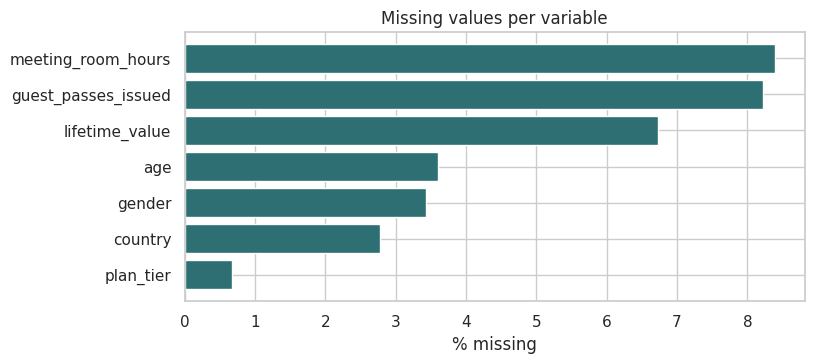

In [7]:
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(missing.index[::-1], missing["pct"][::-1], color="#2E6F73")
ax.set_xlabel("% missing"); ax.set_title("Missing values per variable")
save(fig, "missing"); plt.show()

Missingness is moderate (< 9% per column). `meeting_room_hours` and `guest_passes_issued` can be checked against their usage flags (`uses_meeting_rooms`, `uses_guest_passes`): if the member never used the add-on, a missing value is very likely a structural 0.

In [8]:
for hours_col, flag_col in [("meeting_room_hours", "uses_meeting_rooms"),
                            ("guest_passes_issued", "uses_guest_passes")]:
    print(hours_col, "missing, by", flag_col)
    print(df.loc[df[hours_col].isna(), flag_col].value_counts(), "\n")

meeting_room_hours missing, by uses_meeting_rooms
uses_meeting_rooms
False    904
True     394
Name: count, dtype: int64 

guest_passes_issued missing, by uses_guest_passes
uses_guest_passes
False    1067
True      204
Name: count, dtype: int64 



### 4.3 Inconsistent categories

> 💡 **What this step does:** Lists the different spellings of the same category (e.g. `PT`, `Portucal`, `portugal`). This justifies the manual mapping dictionaries used in cleaning.

In [9]:
for col in ["gender", "country", "industry", "plan_tier"]:
    print(f"{col}: {df[col].nunique()} distinct raw values")
    print(df[col].value_counts(dropna=False).head(15).to_dict(), "\n")

gender: 12 distinct raw values
{'Female': 7414, 'Male': 6172, nan: 530, 'Other': 465, 'female': 169, 'F': 143, ' Female': 141, 'M': 138, 'male': 132, ' Male': 129, 'other': 15, ' Other': 9, 'O': 8} 

country: 33 distinct raw values
{'Portugal': 9959, 'United Kingdom': 1105, 'Germany': 852, 'Spain': 712, 'France': 506, 'Netherlands': 464, nan: 430, 'Other (Europe)': 429, 'Ireland': 232, 'portugal ': 155, 'Portucal': 142, 'PT': 130, 'portugal': 122, 'germany': 24, 'other (europe)': 22} 

industry: 43 distinct raw values
{'Information Technology': 3322, 'Consulting': 1896, 'Marketing & PR': 1835, 'Design & Creative': 1822, 'Finance': 1134, 'Other': 1100, 'Legal': 809, 'Education': 727, 'Unknown': 640, 'Health': 571, 'Real Estate': 528, 'CONSULTING': 86, 'consulting': 76, 'INFORMATION TECHNOLOGY': 54, 'IT': 53} 

plan_tier: 19 distinct raw values
{'flex': 5182, 'hot_desk': 4974, 'full_time': 2323, 'dedicated_desk': 1481, 'private_office': 630, 'Flex': 138, 'FLEX': 133, nan: 105, 'HOT_DESK'

All four categorical variables contain the same concept spelled several ways (case, leading spaces, abbreviations such as `PT`, `UK`, `DE`, typos such as `Portucal`, local names such as `Deutschland` or `España`). They must be harmonised before any grouping.

### 4.4 Dates: mixed formats and a sentinel value

> 💡 **What this step does:** Counts the two date formats and the `1970-01-01` values. 1970-01-01 is the 'zero date' in computer systems, so it is almost certainly a placeholder.

In [10]:
date_cols = ["membership_start", "membership_end", "last_badge_swipe"]
for c in date_cols:
    s = df[c].astype(str)
    print(f"{c}: ISO (yyyy-mm-dd) = {s.str.match(r'^\d{4}-').sum():,} | dd/mm/yyyy = {s.str.match(r'^\d{2}/').sum():,}")
print("\nmembership_end == 1970-01-01:", (df["membership_end"] == "1970-01-01").sum())

membership_start: ISO (yyyy-mm-dd) = 14,826 | dd/mm/yyyy = 639
membership_end: ISO (yyyy-mm-dd) = 15,002 | dd/mm/yyyy = 463


last_badge_swipe: ISO (yyyy-mm-dd) = 14,826 | dd/mm/yyyy = 639

membership_end == 1970-01-01: 3956


- Two date formats coexist. Values such as `31/12/2021` confirm the slash format is **day/month/year**.
- `1970-01-01` (the Unix epoch) appears in about a quarter of `membership_end`. This is not a real date; it is a **placeholder for memberships that have not ended**, i.e. **active members**. We confirm this below: for those rows, `days_since_last_visit` is consistent with a reference date of 2024-01-01 (data extraction).

> 💡 **What this step does:** Tests the placeholder hypothesis: if 1970-01-01 means 'still active' and the data was extracted on 2024-01-01, then `days_since_last_visit` should equal (end date or 2024-01-01) minus the last swipe. It matches for 85% of rows.

In [11]:
def parse_mixed_dates(s):
    iso = pd.to_datetime(s, format="%Y-%m-%d", errors="coerce")
    dmy = pd.to_datetime(s, format="%d/%m/%Y", errors="coerce")
    return iso.fillna(dmy)

tmp = df[date_cols].apply(parse_mixed_dates)
active = tmp["membership_end"].dt.year == 1970
REF_DATE = pd.Timestamp("2024-01-01")
end_or_ref = tmp["membership_end"].where(~active, REF_DATE)
recomputed = (end_or_ref - tmp["last_badge_swipe"]).dt.days
match = (recomputed == df["days_since_last_visit"]).mean()
print(f"days_since_last_visit = (membership_end or 2024-01-01) − last_badge_swipe for {match:.1%} of rows")
print(f"Memberships start between {tmp['membership_start'].min().date()} and {tmp['membership_start'].max().date()}")
print(f"Badge swipes after the 2024-01-01 extraction date: {(tmp['last_badge_swipe'] > REF_DATE).sum()}")

days_since_last_visit = (membership_end or 2024-01-01) − last_badge_swipe for 85.4% of rows
Memberships start between 2021-01-01 and 2023-12-30
Badge swipes after the 2024-01-01 extraction date: 34


### 4.5 Impossible or suspicious values

> 💡 **What this step does:** A set of logic checks: ages outside 18–80, negative counts, end dates before start dates, and swipes after the extraction date.

In [12]:
checks = {
    "age < 18": (df["age"] < 18).sum(),
    "age > 80": (df["age"] > 80).sum(),
    "negative total_visits": (df["total_visits"] < 0).sum(),
    "negative meeting_room_hours": (df["meeting_room_hours"] < 0).sum(),
    "negative event_space_hours": (df["event_space_hours"] < 0).sum(),
    "negative guest_passes_issued": (df["guest_passes_issued"] < 0).sum(),
    "negative n_renewals": (df["n_renewals"] < 0).sum(),
    "negative n_colleagues": (df["n_colleagues_on_account"] < 0).sum(),
    "negative days_since_last_visit": (df["days_since_last_visit"] < 0).sum(),
    "plan_days_per_week not in {2,3,5,7}": (~df["plan_days_per_week"].isin([2, 3, 5, 7])).sum(),
    "membership_end < membership_start": ((tmp["membership_end"] < tmp["membership_start"]) & ~active).sum(),
    "last_badge_swipe < membership_start": (tmp["last_badge_swipe"] < tmp["membership_start"]).sum(),
    "last_badge_swipe after extraction date": (tmp["last_badge_swipe"] > REF_DATE).sum(),
}
pd.Series(checks, name="n_rows").to_frame()

,n_rows
age < 18,98
age > 80,53
negative total_visits,42
negative meeting_room_hours,16
negative event_space_hours,8
negative guest_passes_issued,7
negative n_renewals,66
negative n_colleagues,566
negative days_since_last_visit,56
"plan_days_per_week not in {2,3,5,7}",97


### 4.6 Plan tier ↔ plan days per week

> 💡 **What this step does:** Cross-tabulates tier and days per week. Each tier has exactly one valid number of days, so the two columns carry the same information and can repair each other.

In [13]:
tier_key = df["plan_tier"].str.lower().str.replace(r"[\s_]", "", regex=True)
pd.crosstab(tier_key, df["plan_days_per_week"])

plan_days_per_week,0,2,3,5,7,9
plan_tier,,,,,,
dedicateddesk,3,0,0,1543,0,6
flex,20,0,5411,0,0,22
fulltime,5,0,0,2460,0,10
hotdesk,14,5186,0,0,0,15
privateoffice,1,0,0,0,663,1


Each tier maps to **exactly one** entitlement (hot_desk = 2, flex = 3, dedicated_desk = 5, full_time = 5, private_office = 7). The few 0 and 9 values are entry errors, and missing `plan_tier` can be recovered from `plan_days_per_week` when that value is unambiguous (2, 3 or 7).

Note: `plan_days_per_week` is therefore **redundant** with `plan_tier` and should not enter the clustering as an independent variable.

## 5. Cleaning (rule-based only)
At this stage we only apply **deterministic corrections** (format fixes, harmonisation, recovering values that follow from other columns) and **flag** impossible values as missing. Statistical imputation and outlier treatment are left for Deliverable 2, so that they can be decided together with feature selection.

> 💡 **What this step does:** The cleaning function: (1) drop duplicates, (2) harmonise categories with mapping dictionaries, (3) repair tier and days from each other, (4) convert lifetime value to a number, (5) turn the 1970 placeholder into an `is_active` flag, (6) set impossible values to missing, (7) fill structural zeros. Statistical imputation is left for Deliverable 2 because it depends on which features are used for clustering.

In [14]:
GENDER_MAP = {"female": "Female", "f": "Female", "male": "Male", "m": "Male", "other": "Other", "o": "Other"}

COUNTRY_MAP = {
    "portugal": "Portugal", "portucal": "Portugal", "pt": "Portugal",
    "united kingdom": "United Kingdom", "uk": "United Kingdom", "u.k.": "United Kingdom", "gb": "United Kingdom",
    "germany": "Germany", "deutschland": "Germany", "de": "Germany",
    "spain": "Spain", "espana": "Spain", "españa": "Spain", "es": "Spain",
    "france": "France", "fr": "France",
    "netherlands": "Netherlands", "the netherlands": "Netherlands", "holland": "Netherlands", "nl": "Netherlands",
    "ireland": "Ireland", "ie": "Ireland",
    "other (europe)": "Other (Europe)",
}

INDUSTRY_MAP = {
    "information technology": "Information Technology", "it": "Information Technology", "tech": "Information Technology",
    "consulting": "Consulting",
    "marketing & pr": "Marketing & PR", "marketing/pr": "Marketing & PR", "marketing and pr": "Marketing & PR",
    "design & creative": "Design & Creative", "design/creative": "Design & Creative", "design and creative": "Design & Creative",
    "finance": "Finance", "legal": "Legal", "education": "Education", "health": "Health",
    "real estate": "Real Estate", "realestate": "Real Estate", "real-estate": "Real Estate",
    "other": "Other", "unknown": np.nan,   # 'Unknown' is a missing value in disguise
}

TIER_MAP = {"hotdesk": "hot_desk", "flex": "flex", "dedicateddesk": "dedicated_desk",
            "fulltime": "full_time", "privateoffice": "private_office"}
TIER_ORDER = ["hot_desk", "flex", "dedicated_desk", "full_time", "private_office"]
TIER_DAYS = {"hot_desk": 2, "flex": 3, "dedicated_desk": 5, "full_time": 5, "private_office": 7}

def norm(s):
    return s.astype("string").str.strip().str.lower()

def clean(data):
    d = data.drop_duplicates().copy()

    # categoricals
    d["gender"] = norm(d["gender"]).map(GENDER_MAP)
    d["country"] = norm(d["country"]).map(COUNTRY_MAP)
    d["industry"] = norm(d["industry"]).map(INDUSTRY_MAP)
    d["plan_tier"] = norm(d["plan_tier"]).str.replace(r"[\s_]", "", regex=True).map(TIER_MAP)

    # plan tier <-> days: fix invalid days from tier, recover tier from unambiguous days
    d.loc[~d["plan_days_per_week"].isin([2, 3, 5, 7]), "plan_days_per_week"] = np.nan
    d["plan_days_per_week"] = d["plan_days_per_week"].fillna(d["plan_tier"].map(TIER_DAYS))
    days_to_tier = {2: "hot_desk", 3: "flex", 7: "private_office"}
    d["plan_tier"] = d["plan_tier"].fillna(d["plan_days_per_week"].map(days_to_tier))
    d["plan_tier"] = pd.Categorical(d["plan_tier"], categories=TIER_ORDER, ordered=True)

    # numeric formats
    d["lifetime_value"] = pd.to_numeric(d["lifetime_value"].astype(str).str.replace(",", ""), errors="coerce")
    d["uses_print"] = d["uses_print"].astype(bool)

    # dates + active flag (1970-01-01 sentinel)
    for c in date_cols:
        d[c] = parse_mixed_dates(d[c].astype(str))
    d["is_active"] = d["membership_end"].dt.year == 1970
    d.loc[d["is_active"], "membership_end"] = pd.NaT

    # impossible values -> NaN (treated in Deliverable 2)
    d.loc[(d["age"] < 18) | (d["age"] > 80), "age"] = np.nan
    non_negative = ["total_visits", "meeting_room_hours", "event_space_hours", "guest_passes_issued",
                    "n_renewals", "n_colleagues_on_account", "lifetime_value"]
    for c in non_negative:
        d.loc[d[c] < 0, c] = np.nan
    d.loc[d["days_since_last_visit"] < 0, "days_since_last_visit"] = np.nan
    bad_dates = ((d["membership_end"] < d["membership_start"]) | (d["last_badge_swipe"] < d["membership_start"])
                 | (d["last_badge_swipe"] > REF_DATE))
    d["date_inconsistency"] = bad_dates

    # structural zeros: add-on never used -> 0 usage
    d.loc[d["meeting_room_hours"].isna() & ~d["uses_meeting_rooms"], "meeting_room_hours"] = 0
    d.loc[d["guest_passes_issued"].isna() & ~d["uses_guest_passes"], "guest_passes_issued"] = 0

    return d.reset_index(drop=True)

dfc = clean(df)
print(f"Rows after cleaning: {len(dfc):,}")
for col in ["gender", "country", "industry", "plan_tier"]:
    print(f"{col}: {dfc[col].nunique()} categories, {dfc[col].isna().sum()} missing")

Rows after cleaning: 15,450
gender: 3 categories, 530 missing
country: 8 categories, 429 missing
industry: 10 categories, 693 missing
plan_tier: 5 categories, 49 missing


In [15]:
remaining = dfc.isna().sum()
remaining[remaining > 0].sort_values(ascending=False).to_frame("missing_after_cleaning")

,missing_after_cleaning
membership_end,3954
lifetime_value,1413
age,708
industry,693
n_colleagues_on_account,565
gender,530
country,429
meeting_room_hours,409
guest_passes_issued,210
n_renewals,66


**Remaining issues for Deliverable 2:** missing `lifetime_value` (the key value variable), `age`, `gender`, `country`, `industry`, and the values we flagged as impossible. A KNN or model-based imputation using tier and usage is a natural option for `lifetime_value`; demographics can use a mode/"Unknown" category since they are unlikely to be clustering inputs.

## 6. Univariate Analysis

### 6.1 Membership status, tier and account type

> 💡 **What this step does:** Distribution of membership status, plan tier and account type.

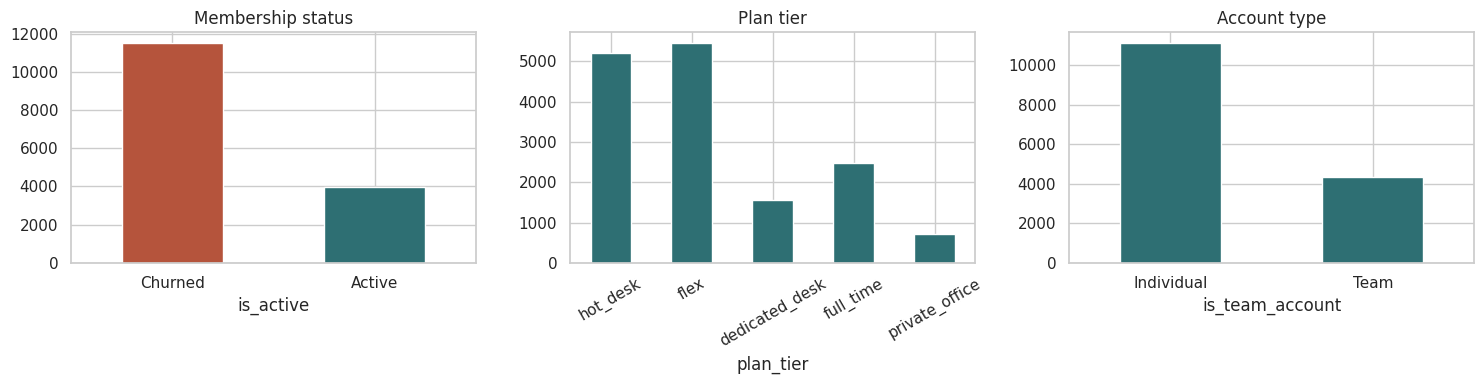

is_active
churned   0.74
active    0.26
Name: proportion, dtype: float64


In [16]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
dfc["is_active"].map({True: "Active", False: "Churned"}).value_counts().plot.bar(ax=axes[0], color=["#B5543C", "#2E6F73"])
axes[0].set_title("Membership status"); axes[0].tick_params(axis="x", rotation=0)
dfc["plan_tier"].value_counts().reindex(TIER_ORDER).plot.bar(ax=axes[1], color="#2E6F73")
axes[1].set_title("Plan tier"); axes[1].tick_params(axis="x", rotation=30)
dfc["is_team_account"].map({True: "Team", False: "Individual"}).value_counts().plot.bar(ax=axes[2], color="#2E6F73")
axes[2].set_title("Account type"); axes[2].tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()
print(dfc["is_active"].value_counts(normalize=True).rename({True: "active", False: "churned"}))

Only about **one in four members is still active**: churn is the dominant story in this base. The tier mix is dominated by the cheaper plans (hot desk + flex ≈ two-thirds).

### 6.2 Numeric distributions

> 💡 **What this step does:** Histograms of the main numeric variables, with skewness in each title. Skewness above 1 means a long right tail.

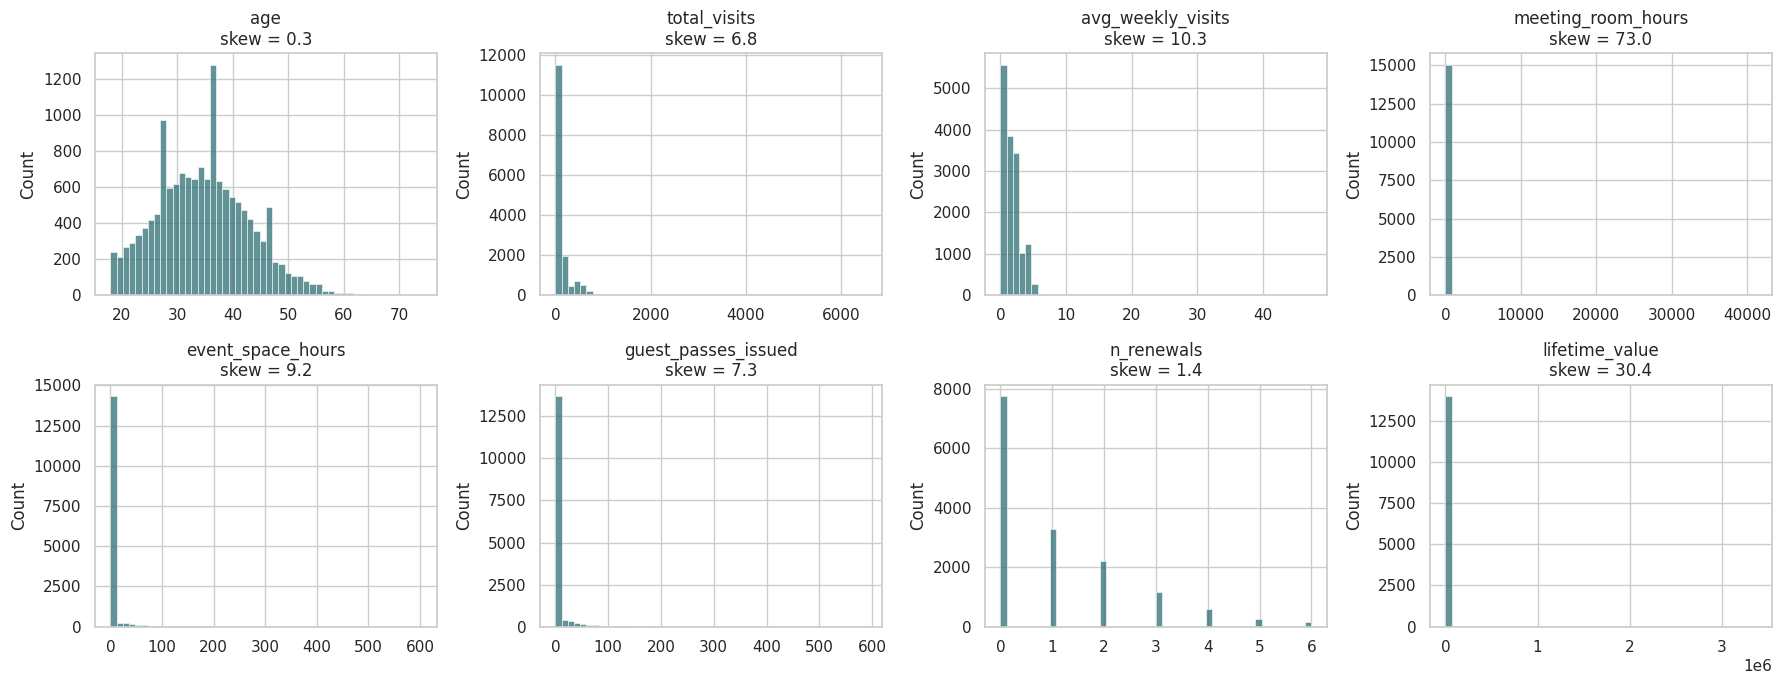

In [17]:
dist_cols = ["age", "total_visits", "avg_weekly_visits", "meeting_room_hours", "event_space_hours",
             "guest_passes_issued", "n_renewals", "lifetime_value"]
fig, axes = plt.subplots(2, 4, figsize=(18, 7))
for ax, c in zip(axes.flat, dist_cols):
    sns.histplot(dfc[c].dropna(), bins=50, ax=ax, color="#2E6F73")
    ax.set_title(f"{c}\nskew = {dfc[c].skew():.1f}")
    ax.set_xlabel("")
plt.tight_layout(); plt.show()

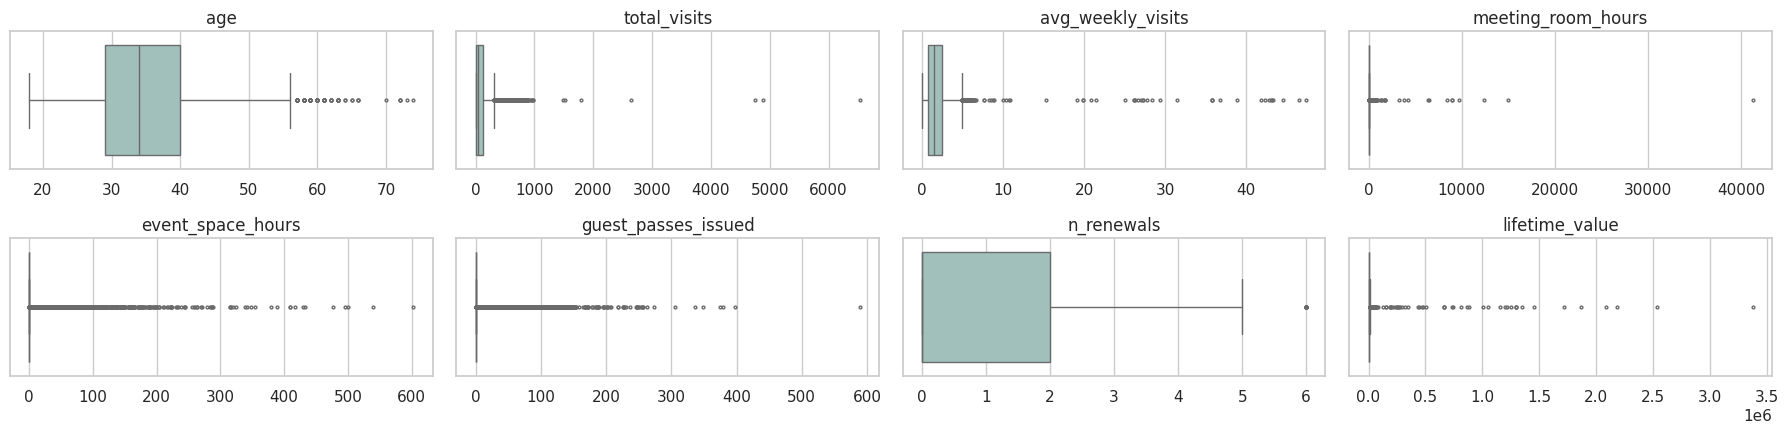

In [18]:
fig, axes = plt.subplots(2, 4, figsize=(18, 4.5))
for ax, c in zip(axes.flat, dist_cols):
    sns.boxplot(x=dfc[c].dropna(), ax=ax, color="#9CC5C0", fliersize=2)
    ax.set_title(c); ax.set_xlabel("")
plt.tight_layout(); plt.show()

> 💡 **What this step does:** Compares the maximum with the 99th percentile. A ratio far above 1 shows extreme values that would dominate a distance-based algorithm such as K-Means.

In [19]:
q = dfc[dist_cols].quantile([0.5, 0.99, 1.0]).T
q.columns = ["median", "p99", "max"]
q["max / p99"] = q["max"] / q["p99"]
q

,median,p99,max,max / p99
age,34.00,55.00,74.00,1.35
total_visits,35.00,693.93,"6,530.00",9.41
avg_weekly_visits,1.42,5.32,47.40,8.91
meeting_room_hours,0.00,319.92,"41,220.00",128.84
event_space_hours,0.00,127.44,602.80,4.73
guest_passes_issued,0.00,115.00,589.00,5.12
n_renewals,0.00,5.00,6.00,1.20
lifetime_value,901.86,"25,729.67","3,371,260.00",131.03


Usage and value variables are **heavily right-skewed**, with a few extreme values far beyond the 99th percentile (e.g. `meeting_room_hours`, `lifetime_value`, `total_visits`). These would dominate distance-based algorithms such as K-Means. Options for Deliverable 2: log transform, winsorising at p99, or a robust scaler — and checking whether the extremes are data errors or genuine VIP accounts.

### 6.3 Add-on adoption

> 💡 **What this step does:** Share of members using each add-on.

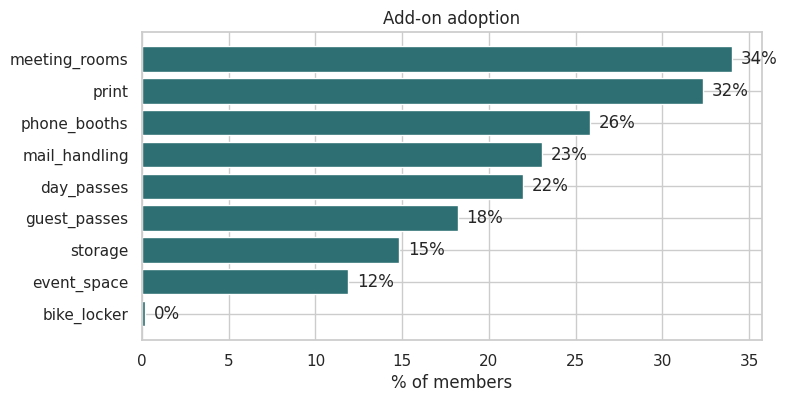

In [20]:
addon_cols = [c for c in dfc.columns if c.startswith("uses_")]
adoption = dfc[addon_cols].mean().sort_values()
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(adoption.index.str.replace("uses_", ""), adoption * 100, color="#2E6F73")
ax.set_xlabel("% of members"); ax.set_title("Add-on adoption")
for i, v in enumerate(adoption * 100):
    ax.text(v + 0.5, i, f"{v:.0f}%", va="center")
save(fig, "addons"); plt.show()

Meeting rooms are the most used add-on (~34%). `uses_bike_locker` is almost constant (< 0.2%) and carries no information for clustering, so it is a candidate for removal.

### 6.4 Demographics

> 💡 **What this step does:** Age, country and industry. These are mainly useful to describe segments later, not as clustering inputs.

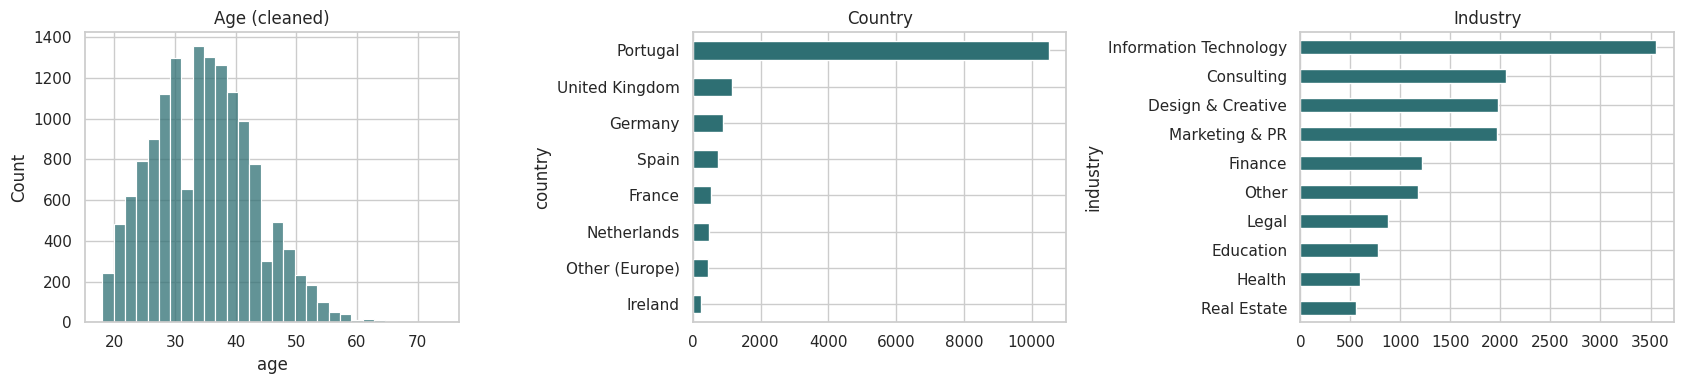

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
sns.histplot(dfc["age"].dropna(), bins=30, ax=axes[0], color="#2E6F73"); axes[0].set_title("Age (cleaned)")
dfc["country"].value_counts().plot.barh(ax=axes[1], color="#2E6F73"); axes[1].set_title("Country"); axes[1].invert_yaxis()
dfc["industry"].value_counts().plot.barh(ax=axes[2], color="#2E6F73"); axes[2].set_title("Industry"); axes[2].invert_yaxis()
plt.tight_layout(); plt.show()

About two-thirds of members are based in Portugal; IT, Consulting, Marketing & PR and Design & Creative are the largest industries.

## 7. Bivariate Analysis

### 7.1 Value by plan tier

> 💡 **What this step does:** Summary per tier: members, median lifetime value, total revenue, share still active. Comparing share of members with share of revenue shows where value is concentrated.

In [22]:
tier_summary = dfc.groupby("plan_tier", observed=True).agg(
    members=("member_id", "count"),
    median_ltv=("lifetime_value", "median"),
    total_ltv=("lifetime_value", "sum"),
    active_rate=("is_active", "mean"),
    median_renewals=("n_renewals", "median"),
)
tier_summary["share_members"] = tier_summary["members"] / tier_summary["members"].sum()
tier_summary["share_revenue"] = tier_summary["total_ltv"] / tier_summary["total_ltv"].sum()
tier_summary

,members,median_ltv,total_ltv,active_rate,median_renewals,share_members,share_revenue
plan_tier,,,,,,,
hot_desk,5212,321.31,"9,682,415.84",0.13,0.00,0.34,0.11
flex,5449,"1,253.81","18,156,877.90",0.20,0.00,0.35,0.20
dedicated_desk,1549,"10,387.85","19,091,408.32",0.57,2.00,0.10,0.21
full_time,2471,"4,694.10","22,494,119.19",0.38,1.00,0.16,0.25
private_office,720,"19,905.69","20,737,813.43",0.46,2.00,0.05,0.23


Note that `dedicated_desk` has a **higher median lifetime value than `full_time`**, even though `full_time` is listed above it in the tier order. The tier ordering in the dictionary is not the same as a value ordering — a point to raise with ACDC.

### 7.2 Churn by tier and account type

> 💡 **What this step does:** Share of members still active, by tier and by account type.

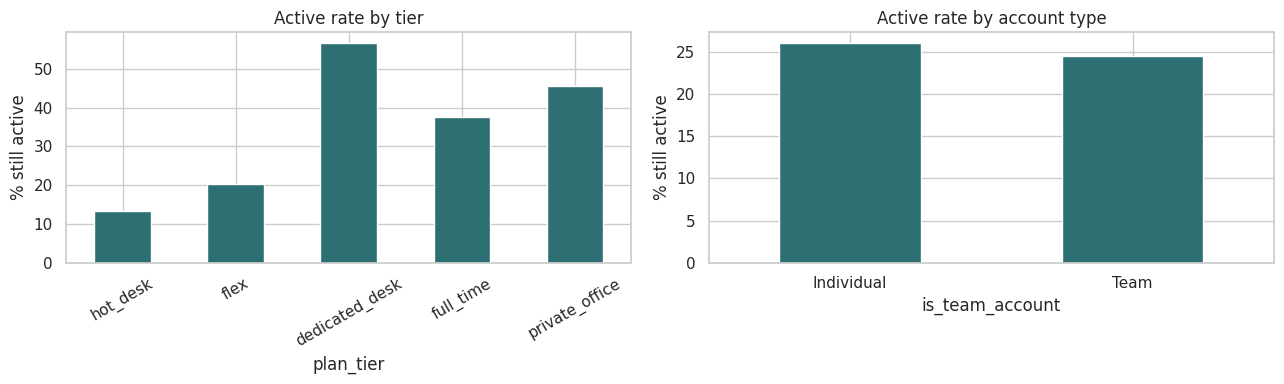

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
(dfc.groupby("plan_tier", observed=True)["is_active"].mean() * 100).plot.bar(ax=axes[0], color="#2E6F73")
axes[0].set_ylabel("% still active"); axes[0].set_title("Active rate by tier"); axes[0].tick_params(axis="x", rotation=30)
(dfc.groupby("is_team_account")["is_active"].mean() * 100).rename({True: "Team", False: "Individual"}).plot.bar(ax=axes[1], color="#2E6F73")
axes[1].set_ylabel("% still active"); axes[1].set_title("Active rate by account type"); axes[1].tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.show()

### 7.3 Correlations

> 💡 **What this step does:** Spearman correlation matrix. Spearman uses ranks, so it is not distorted by skew and extreme values the way Pearson is.

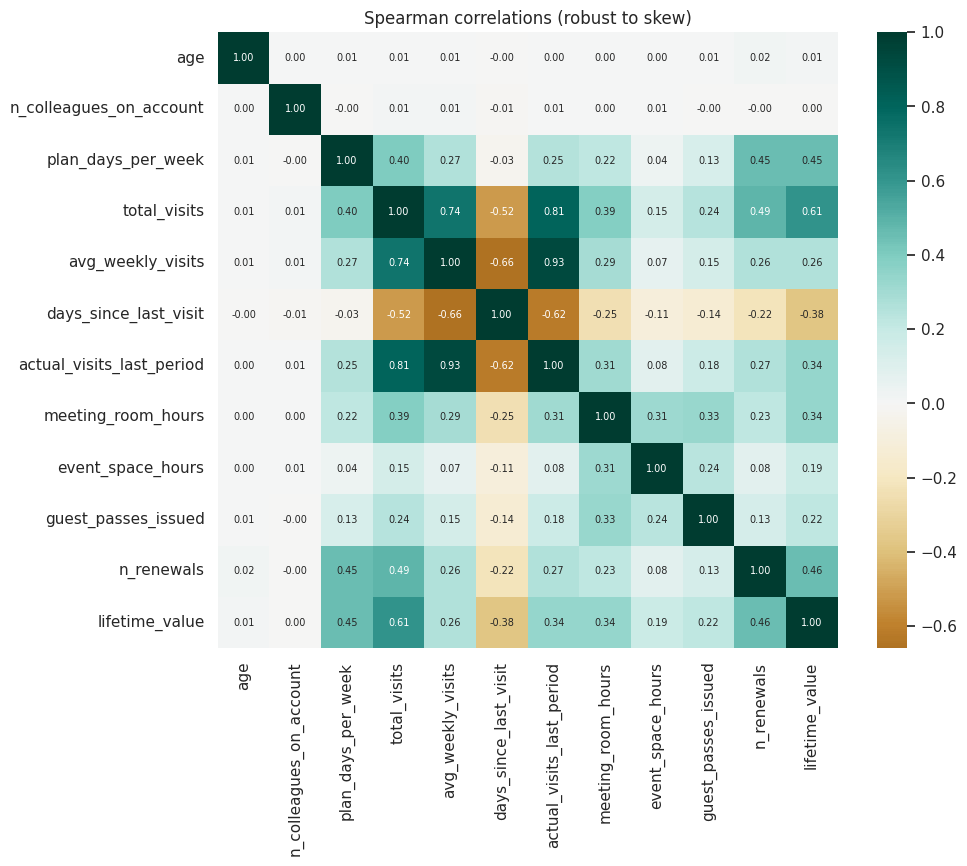

In [24]:
corr_cols = ["age", "n_colleagues_on_account", "plan_days_per_week", "total_visits", "avg_weekly_visits",
             "days_since_last_visit", "actual_visits_last_period", "meeting_room_hours", "event_space_hours",
             "guest_passes_issued", "n_renewals", "lifetime_value"]
corr = dfc[corr_cols].corr(method="spearman")
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, cmap="BrBG", center=0, annot=True, fmt=".2f", annot_kws={"size": 7}, ax=ax)
ax.set_title("Spearman correlations (robust to skew)")
plt.show()

We use **Spearman** because of the strong skew. Strongly correlated pairs (e.g. `total_visits` with `n_renewals` and `lifetime_value`, which all grow with tenure) mean that several raw variables mostly measure **how long someone has been a member**. Feeding all of them to a clustering algorithm would over-weight tenure. This motivates the normalised features in Section 8.

## 8. Feature Engineering

Most raw usage and value variables are **cumulative**, so they mix *intensity* with *time*. A member who joined three years ago will always look "bigger" than one who joined three months ago. The engineered features below separate these effects.

| Feature | Definition | Perspective | Why it matters |
|---|---|---|---|
| `tenure_months` | (end date or 2024-01-01 − start) / 30.44 | Value | Loyalty; controls for time |
| `ltv_per_month` | lifetime_value / tenure_months | Value | Spending intensity, independent of tenure |
| `visits_per_month` | total_visits / tenure_months | Behavioral | Attendance intensity |
| `utilisation_rate` | actual_visits_last_period / entitled_visits_last_period | Behavioral | Do members use what they pay for? |
| `n_addons` | number of add-on flags = True | Behavioral | Breadth of service use |
| `meeting_hours_per_month` | meeting_room_hours / tenure_months | Behavioral | Collaboration / client-facing work |
| `renewal_rate` | n_renewals / tenure_months × 12 | Value | Commitment (renewals per year) |
| `account_size` | n_colleagues_on_account + 1 | Value | Seats per account |
| `ltv_per_seat` | lifetime_value / account_size | Value | Revenue per person |

> 💡 **What this step does:** Creates the engineered features. Cumulative totals grow with time, so dividing by tenure measures intensity instead of how long someone has been a member. Utilisation compares actual visits with the visits the plan entitles the member to.

In [25]:
def engineer(d):
    f = d.copy()
    end = f["membership_end"].fillna(REF_DATE)
    f["tenure_months"] = ((end - f["membership_start"]).dt.days / 30.44).where(lambda s: s > 0)
    f["ltv_per_month"] = f["lifetime_value"] / f["tenure_months"]
    f["visits_per_month"] = f["total_visits"] / f["tenure_months"]
    f["utilisation_rate"] = (f["actual_visits_last_period"] /
                             f["entitled_visits_last_period"].replace(0, np.nan))
    f["n_addons"] = f[addon_cols].sum(axis=1)
    f["meeting_hours_per_month"] = f["meeting_room_hours"] / f["tenure_months"]
    f["renewal_rate"] = f["n_renewals"] / f["tenure_months"] * 12
    f["account_size"] = f["n_colleagues_on_account"].fillna(0) + 1
    f["ltv_per_seat"] = f["lifetime_value"] / f["account_size"]
    return f

feat = engineer(dfc)
eng_cols = ["tenure_months", "ltv_per_month", "visits_per_month", "utilisation_rate", "n_addons",
            "meeting_hours_per_month", "renewal_rate", "account_size", "ltv_per_seat"]
feat[eng_cols].describe().T

,count,mean,std,min,25%,50%,75%,max
tenure_months,"15,298.00",12.31,11.13,0.07,2.14,9.28,20.93,35.97
ltv_per_month,"13,906.00",417.41,"2,832.20",0.00,128.37,190.73,307.12,"93,717.95"
visits_per_month,"15,256.00",7.47,6.50,0.00,3.04,6.09,10.39,206.56
utilisation_rate,"15,440.00",0.52,0.31,0.00,0.24,0.52,0.80,1.00
n_addons,"15,450.00",1.82,1.50,0.00,1.00,1.00,3.00,8.00
meeting_hours_per_month,"14,894.00",1.85,20.48,0.00,0.00,0.00,0.83,"1,842.49"
renewal_rate,"15,233.00",2.17,14.93,0.00,0.00,0.00,1.28,913.20
account_size,"15,450.00",1.57,1.14,1.00,1.00,1.00,2.00,10.00
ltv_per_seat,"14,037.00","5,412.28","58,439.06",0.00,186.58,653.15,"3,955.16","3,371,260.00"


### 8.1 Utilisation: are members using what they pay for?

> 💡 **What this step does:** Utilisation distribution per tier. The dashed line at 1 means the member used every day they paid for.

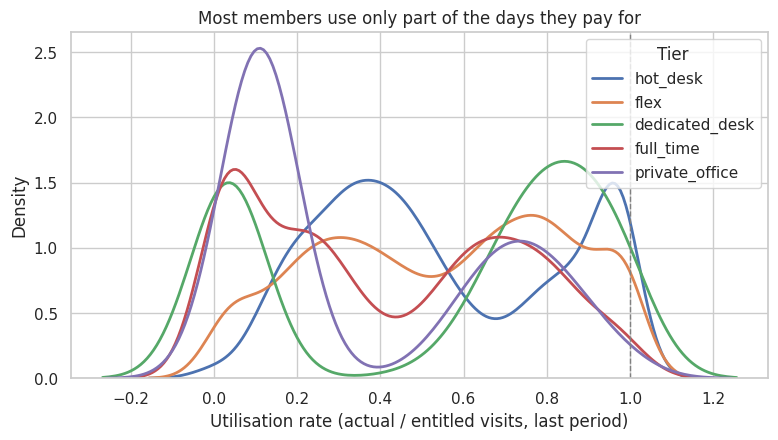

,median_utilisation
plan_tier,
hot_desk,0.46
flex,0.57
dedicated_desk,0.74
full_time,0.33
private_office,0.15


In [26]:
fig, ax = plt.subplots(figsize=(9, 4.5))
for tier in TIER_ORDER:
    s = feat.loc[feat["plan_tier"] == tier, "utilisation_rate"].clip(upper=1.5).dropna()
    sns.kdeplot(s, ax=ax, label=tier, linewidth=2)
ax.axvline(1, color="grey", ls="--", lw=1)
ax.set_xlabel("Utilisation rate (actual / entitled visits, last period)")
ax.set_title("Most members use only part of the days they pay for")
ax.legend(title="Tier")
save(fig, "utilisation"); plt.show()

feat.groupby("plan_tier", observed=True)["utilisation_rate"].median().to_frame("median_utilisation")

### 8.2 Engineered features vs. churn

> 💡 **What this step does:** Compares medians of the engineered features between active and churned members.

In [27]:
cmp = feat.groupby("is_active")[["utilisation_rate", "visits_per_month", "n_addons",
                                 "ltv_per_month", "renewal_rate"]].median().T
cmp.columns = ["Churned", "Active"]
cmp

,Churned,Active
utilisation_rate,0.57,0.23
visits_per_month,7.08,3.61
n_addons,1.00,2.00
ltv_per_month,183.80,249.89
renewal_rate,0.00,0.80


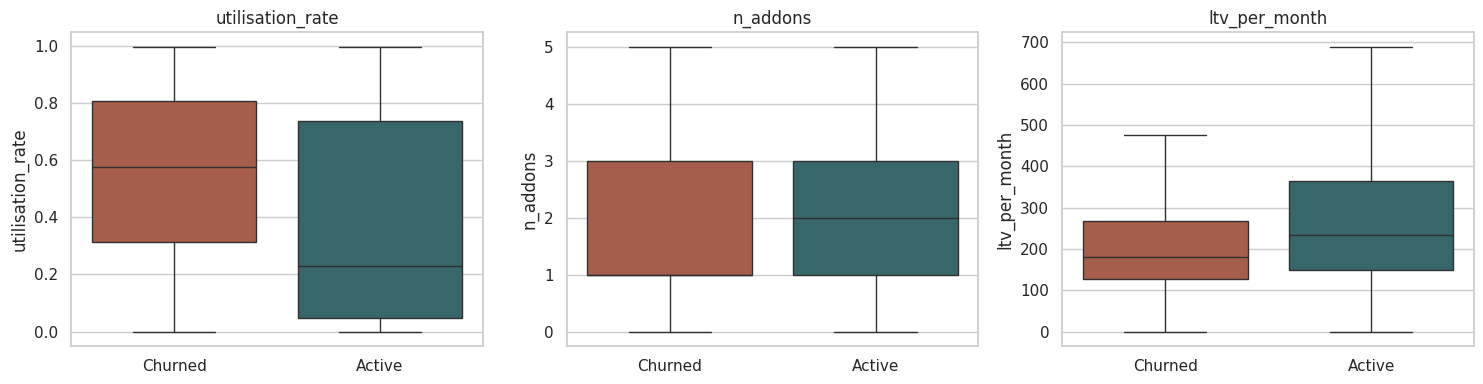

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, c in zip(axes, ["utilisation_rate", "n_addons", "ltv_per_month"]):
    data = feat[[c, "is_active"]].dropna()
    data["status"] = data["is_active"].map({True: "Active", False: "Churned"})
    upper = data[c].quantile(0.98)
    sns.boxplot(data=data[data[c] <= upper], x="status", y=c, ax=ax,
                palette={"Active": "#2E6F73", "Churned": "#B5543C"}, showfliers=False)
    ax.set_title(c); ax.set_xlabel("")
plt.tight_layout(); save(fig, "active_vs_churned"); plt.show()

**Counter-intuitive finding:** active members have *lower* utilisation and fewer visits per month than churned members, but more add-ons, higher monthly revenue and more renewals. The likely explanation is tier: the premium plans (private office, full time) have low utilisation but high retention — those members (often teams) pay for **guaranteed availability**, not daily attendance. Hot-desk and flex members, by contrast, come often and then leave.

Implication: utilisation on its own is **not** an engagement score; it must be read together with tier and account type. This is exactly the kind of interaction clustering can capture.

### 8.3 Value perspective: monthly revenue by tier

> 💡 **What this step does:** Monthly revenue per tier, without outliers for readability.

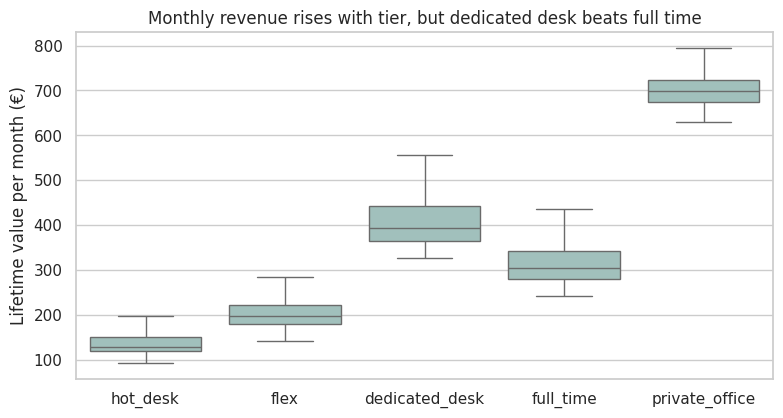

,median_ltv_per_month
plan_tier,
hot_desk,129.30
flex,197.43
dedicated_desk,394.65
full_time,304.96
private_office,697.77


In [29]:
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.boxplot(data=feat, x="plan_tier", y="ltv_per_month", order=TIER_ORDER, showfliers=False,
            color="#9CC5C0", ax=ax)
ax.set_xlabel(""); ax.set_ylabel("Lifetime value per month (€)")
ax.set_title("Monthly revenue rises with tier, but dedicated desk beats full time")
save(fig, "ltv_month_tier"); plt.show()
feat.groupby("plan_tier", observed=True)["ltv_per_month"].median().to_frame("median_ltv_per_month")

### 8.4 Redundancy check among engineered features

> 💡 **What this step does:** Checks that the engineered features are not duplicates of each other. Pairs above ~0.8 would mean keeping only one.

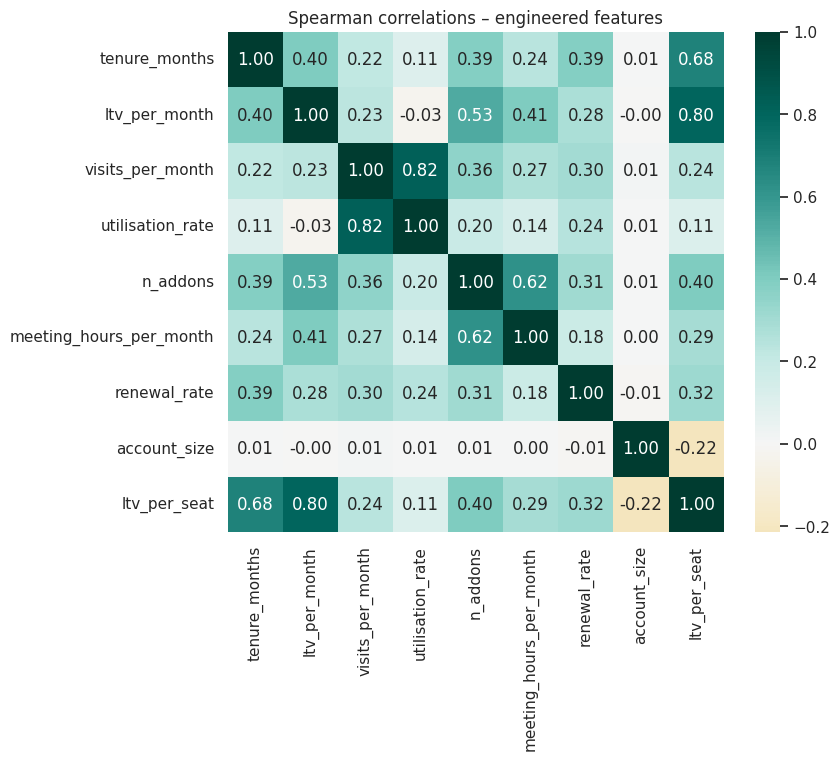

In [30]:
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(feat[eng_cols].corr(method="spearman"), cmap="BrBG", center=0, annot=True, fmt=".2f", ax=ax)
ax.set_title("Spearman correlations – engineered features"); plt.show()

## 9. Summary of Findings

**Data quality (risks for clustering)**
- File-level issues: `;` separator, two date formats, thousands separators in `lifetime_value`, 15 exact duplicates.
- Heavy inconsistency in all categorical variables (up to ~40 spellings for 11 industries); harmonised with explicit mappings.
- `membership_end = 1970-01-01` is a sentinel for **active** members (~26%), not a date — confirmed through `days_since_last_visit`.
- Impossible values (negative counts/hours, age outside 18–80, invalid plan days) flagged as missing; date inconsistencies (end before start, swipes after the extraction date) flagged.
- Strong right skew and extreme values in usage and value variables → need transformation/robust scaling.

**Most important insights**
- Roughly **three in four members have churned**; retention is the central business problem.
- Members use about half of the days they pay for (median utilisation ≈ 52%). Surprisingly, **active members have lower utilisation than churned ones**: premium/team members pay for availability, while low-tier members visit intensively and then leave.
- Revenue is concentrated: private office is ~5% of members but ~23% of lifetime value; hot desk is ~34% of members but ~11% of value.
- Monthly revenue grows with tier, but **dedicated desk outperforms full time**, so the official tier order is not a value order.
- Cumulative variables are driven by tenure; the per-month features separate intensity from time.

**Implications for Deliverable 2**
- Perspectives: **value** (ltv_per_month, tenure, renewal_rate, account size) and **behavioral** (visits_per_month, utilisation, add-ons, meeting hours); demographics only for profiling.
- Drop or avoid redundant/uninformative variables: `plan_days_per_week` (= tier), `uses_bike_locker` (near-constant), raw cumulative totals.
- Expected number of segments: roughly 4–6. The tier/value pattern suggests a premium group, a mid-value committed group and a low-value basic group; the behavioral signals (utilisation, add-on breadth, meeting-room use) suggest these split further into intensive users vs. 'pay-for-access' members. To be tested with several algorithms in Deliverable 2.